# Pulsar timing with PINT (Section 5)

The TOAs come from `pipeline/02_make_toas.sh` (`data/toas.tim`, one per observation, and
`data/toas_within_2021A.tim`, three within NICER 2021A). This notebook builds the initial
frequency step by step and fits the timing model.

| cell | paper item | file |
|---|---|---|
| Within-observation residual slopes | Figure 8, Section 5.3 | `pint_initial_center_prefit.pdf`, `pint_initial_center_postfit.pdf` |
| Residual slopes for the five candidate aliases | Figure 9 (bottom) | `pint_resid_slopes.pdf` |
| Pre-fit residuals of the three initial models | Figure 7 | `prefit_residuals.pdf` |
| Successive frequency estimates | Figure 10 | `initial_frequency_plot.pdf` |
| PINT fit for $f$ and $\dot f$ | Figure 11, Section 5.4 | `pint_prefit_resids.pdf`, `pint_postfit_resids.pdf` |
| Joint confidence ellipse | Figure 12 | `pint_error_ellipse.pdf` |
| Numbers quoted in the paper | Sections 5.3 and 5.4 | printed at the end |

In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import astropy.units as u

import pint.logging
import pint.models
import pint.toa
import pint.residuals
from pint.models import model_builder, PhaseOffset
from pint.fitter import DownhillWLSFitter, WLSFitter

import config
import plotting

pint.logging.setup(level='WARNING')
savedir = config.FIGURE_DIR

## Section 5.3: the initial frequency

The maximum tolerable frequency error is set by the longest gap between TOAs (678 days):
$\Delta f_{\max} = 0.5 / T_{\rm gap} \approx 8.5 \times 10^{-9}$ Hz.

In [2]:
delta_f_max = 0.5 / (678 * 86400)
print(f'maximum tolerable frequency error: {delta_f_max:.2e} Hz')

maximum tolerable frequency error: 8.54e-09 Hz


### Residual slopes of the three TOAs within NICER 2021A for the candidate alias frequencies (Figure 8: central alias; Figure 9 bottom: all five)

center     par f = 0.03377273 Hz -> fit f = 0.03377271489 +/- 3.75e-08 Hz


leftpeak   par f = 0.03377261 Hz -> fit f = 0.03377271489 +/- 3.75e-08 Hz


leftpeak2  par f = 0.03377250 Hz -> fit f = 0.03377271489 +/- 3.75e-08 Hz


rightpeak  par f = 0.03377285 Hz -> fit f = 0.03377271489 +/- 3.75e-08 Hz


rightpeak2 par f = 0.03377297 Hz -> fit f = 0.03377271489 +/- 3.75e-08 Hz


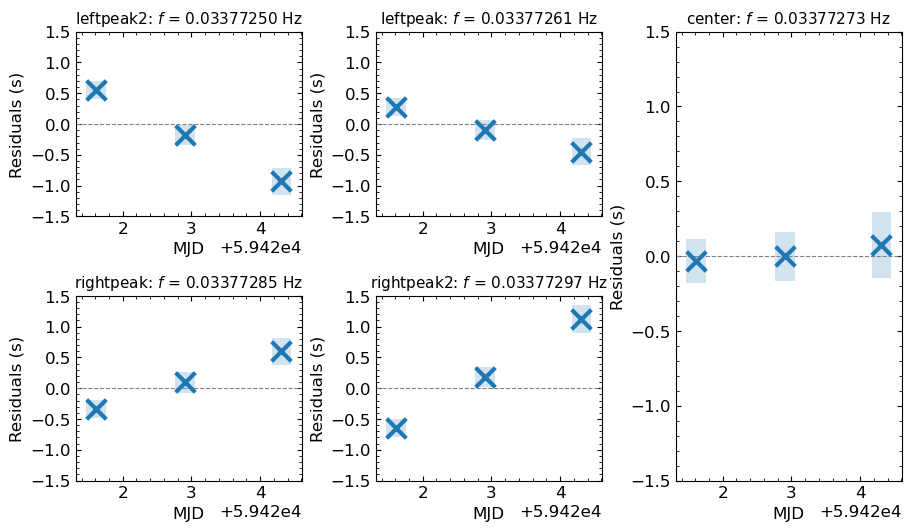

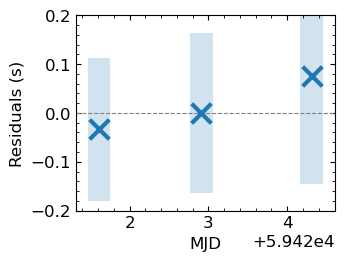

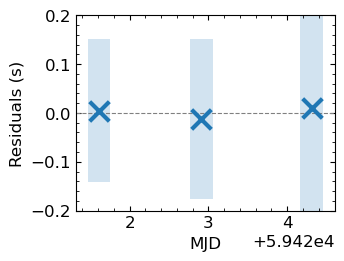

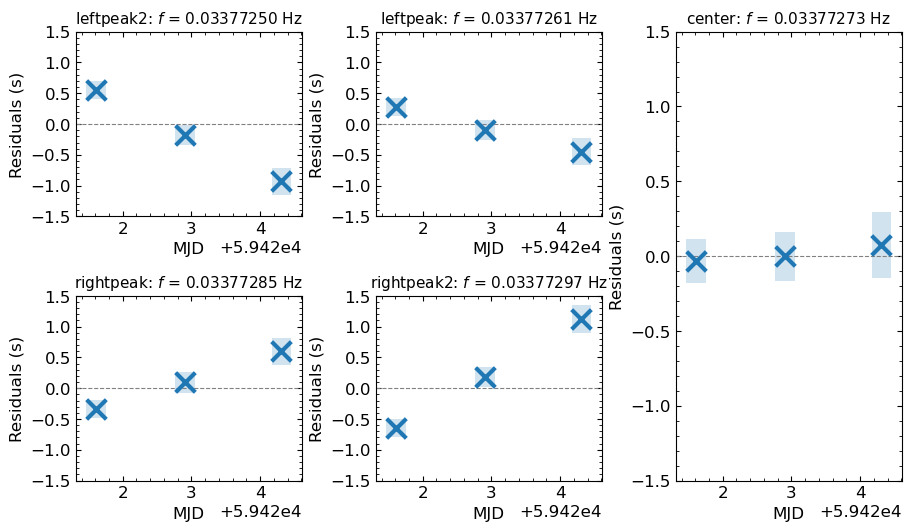

In [3]:
par_files = {'center': 'test_timing_model', 'leftpeak': 'CTCV_leftpeak', 'leftpeak2': 'CTCV_leftpeak2',
             'rightpeak': 'CTCV_rightpeak', 'rightpeak2': 'CTCV_rightpeak2'}
toas_within = pint.toa.get_TOAs(config.TOAS_WITHIN)
mjds_w = toas_within.get_mjds().value
errs_w = toas_within.get_errors().to(u.s).value
bar_width = 0.107 * (np.max(mjds_w) - np.min(mjds_w))

panels = {}
for label, name in par_files.items():
    m = pint.models.get_model(f'{config.DATA_DIR}/{name}.par')
    m.F1.frozen = True
    pre = pint.residuals.Residuals(toas_within, m).time_resids.to(u.s).value
    fitter_w = WLSFitter(toas_within, m)
    fitter_w.fit_toas()
    post = fitter_w.resids.time_resids.to(u.s).value
    panels[label] = (mjds_w, pre, errs_w, float(m.F0.value))
    print(f"{label:10s} par f = {m.F0.value:.8f} Hz -> fit f = {fitter_w.model.F0.value:.11f} +/- {fitter_w.model.F0.uncertainty.value:.2e} Hz")
    if label == 'center':
        f_slope, f_slope_err = fitter_w.model.F0.value, fitter_w.model.F0.uncertainty.value
        plotting.plot_within_residuals(mjds_w, pre, errs_w, bar_width, path=f'{savedir}/pint_initial_center_prefit.pdf')
        plotting.plot_within_residuals(mjds_w, post, errs_w, bar_width, path=f'{savedir}/pint_initial_center_postfit.pdf')

plotting.plot_resid_slopes_montage(panels, bar_width, path=f'{savedir}/pint_resid_slopes.pdf')

### Figure 7: pre-fit residuals of the five TOAs for the three successive initial models

timing_model_z2            f = 0.0337727000 +/- 1.8e-07 Hz, pre-fit wrms 3.475 s
timing_model_resid_slope   f = 0.0337727140 +/- 3.8e-08 Hz, pre-fit wrms 4.028 s
timing_model_centerpeak    f = 0.0337727321 +/- 8.8e-09 Hz, pre-fit wrms 0.575 s


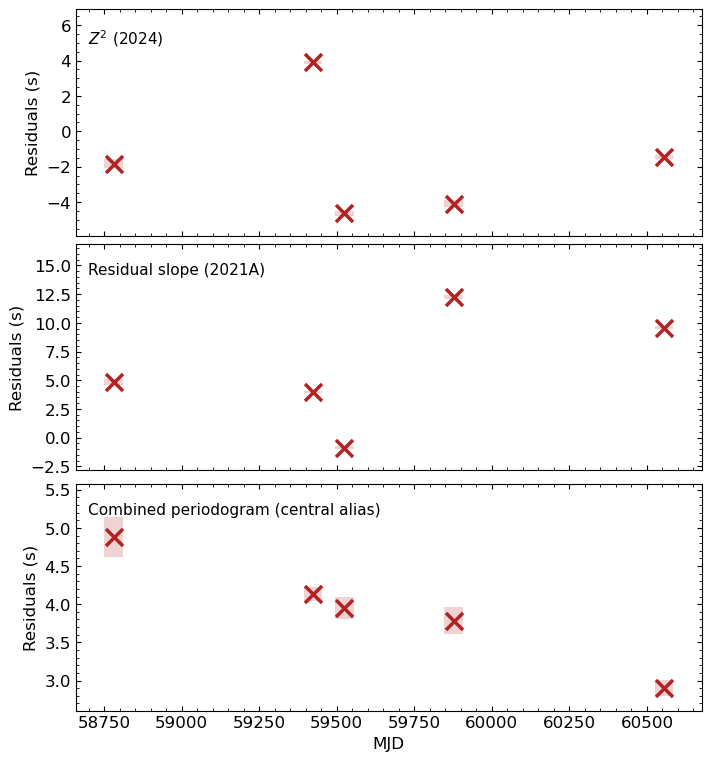

In [4]:
stages = [('timing_model_z2', r'$Z^2$ (2024)'), ('timing_model_resid_slope', 'Residual slope (2021A)'),
          ('timing_model_centerpeak', 'Combined periodogram (central alias)')]
prefit_panels = []
initial = []   # (f, sigma_f) of each stage, for Figure 10
for name, label in stages:
    m, toas_stage = model_builder.get_model_and_toas(f'{config.DATA_DIR}/{name}.par', config.TOAS)
    res = pint.residuals.Residuals(toas_stage, m, subtract_mean=False)
    prefit_panels.append((label, res.toas.get_mjds().value, res.time_resids.to(u.s).value, res.toas.get_errors().to(u.s).value))
    initial.append((float(m.F0.value), float(m.F0.uncertainty_value)))
    print(f'{name:26s} f = {m.F0.value:.10f} +/- {m.F0.uncertainty_value:.1e} Hz, pre-fit wrms {res.rms_weighted().to(u.s).value:.3f} s')

plotting.plot_prefit_montage(prefit_panels, path=f'{savedir}/prefit_residuals.pdf')

## Section 5.4: fit for $f$ and $\dot f$ (with a phase offset) from the central-alias initial model

5 TOAs, MJD 58780.58 d to 60554.68 d
Fitted model using downhill_wls method with 3 free parameters to 5 TOAs
Prefit residuals Wrms = 574518.4385291748 us, Postfit residuals Wrms = 53291.653187901495 us
Chisq = 0.888 for 1 d.o.f. for reduced Chisq of 0.888

PAR                   Prefit                  Postfit            Units
============== ==================== ============================ =====
EPHEM                         DE440 DE440                        None
CLOCK                               TT(BIPM2023)                 None
UNITS                           TDB TDB                          None
START                                                    58780.6 d 
FINISH                                                   60554.7 d 
DILATEFREQ                        N                              None
DMDATA                            N                              None
NTOA                              0                              None 
CHI2                                        

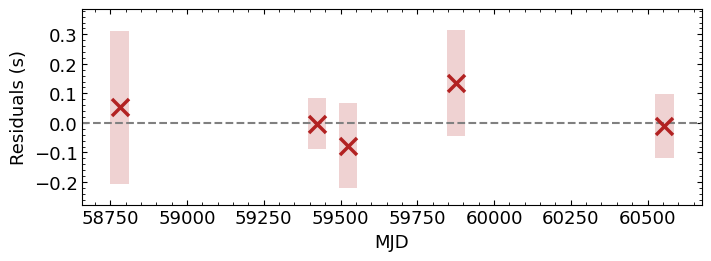

In [5]:
model, toas = model_builder.get_model_and_toas(f'{config.DATA_DIR}/timing_model_centerpeak.par', config.TOAS)
print(f'{len(toas)} TOAs, MJD {toas.get_mjds().min():.2f} to {toas.get_mjds().max():.2f}')

# Figure 11 (left): pre-fit residuals
res = pint.residuals.Residuals(toas, model, subtract_mean=False)
mjds = res.toas.get_mjds().value
pre = res.time_resids.to(u.s).value
errs = res.toas.get_errors().to(u.s).value
plotting.plot_toa_residuals(mjds, pre, errs, ylim=(np.min(pre) - 0.3, np.max(pre) * 1.1), path=f'{savedir}/pint_prefit_resids.pdf')

# Fit F0, F1 and a phase offset
model.F0.frozen = False
model.F1.frozen = False
model.add_component(PhaseOffset())
model.PHOFF.frozen = False
fitter = DownhillWLSFitter(toas, model)
fitter.fit_toas()
print(fitter.print_summary())

# Figure 11 (right): post-fit residuals
post = fitter.resids.time_resids.to(u.s).value
plotting.plot_toa_residuals(mjds, post, errs, zero_line=True, ylim=(np.min(post) - 0.2, np.max(post) + 0.25), path=f'{savedir}/pint_postfit_resids.pdf')

### Figure 12: joint confidence ellipse of $f$ and $\dot f$

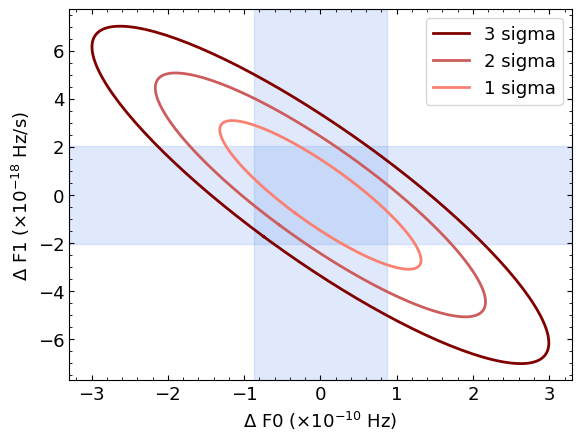

In [6]:
param_names = [label[0] for label in fitter.parameter_correlation_matrix.labels[0]]
i0, i1 = param_names.index('F0'), param_names.index('F1')
full_corr = fitter.parameter_correlation_matrix.matrix
corr = np.array([[full_corr[i0, i0], full_corr[i0, i1]], [full_corr[i1, i0], full_corr[i1, i1]]])
sigmas = np.array([fitter.get_fitparams_uncertainty()[p] for p in ['F0', 'F1']])

plotting.plot_error_ellipse(corr, sigmas, path=f'{savedir}/pint_error_ellipse.pdf')

### The $f$-only model: $\dot f$ is consistent with zero, so the reduced model gives the adopted $f$

In [7]:
model.F1.frozen = True
fitter2 = DownhillWLSFitter(toas, model)
fitter2.fit_toas()
print(fitter2.print_summary())

Fitted model using downhill_wls method with 2 free parameters to 5 TOAs
Prefit residuals Wrms = 574518.4385291748 us, Postfit residuals Wrms = 53306.39512082762 us
Chisq = 0.889 for 2 d.o.f. for reduced Chisq of 0.444

PAR                   Prefit                  Postfit            Units
============== ==================== ============================ =====
EPHEM                         DE440 DE440                        None
CLOCK                               TT(BIPM2023)                 None
UNITS                           TDB TDB                          None
START                                                    58780.6 d 
FINISH                                                   60554.7 d 
DILATEFREQ                        N                              None
DMDATA                            N                              None
NTOA                              0                              None 
CHI2                                                    0.888511  
CHI2R          

### Figure 10: the successive initial-frequency estimates compared with the final fit

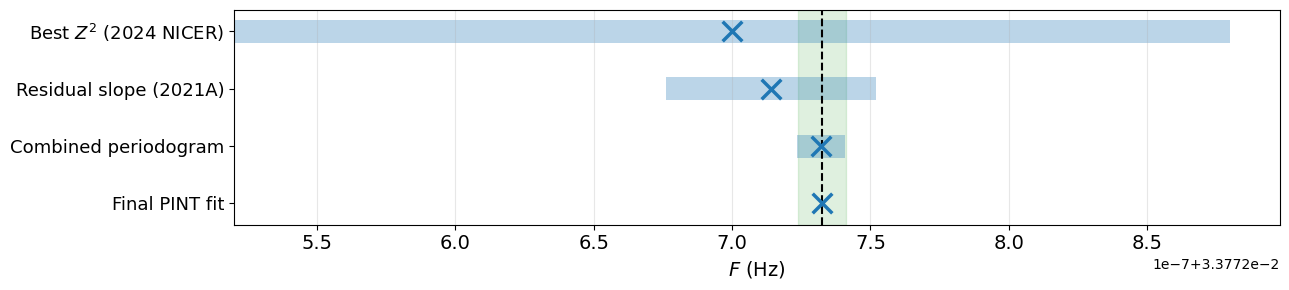

In [8]:
labels = [r'Best $Z^2$ (2024 NICER)', r'Residual slope (2021A)', r'Combined periodogram', r'Final PINT fit']
freqs = np.array([f for f, _ in initial] + [float(fitter2.model.F0.value)])
uncerts = np.array([df for _, df in initial] + [float(fitter2.model.F0.uncertainty_value)])
plotting.plot_initial_frequency(labels, freqs, uncerts, delta_f_max, path=f'{savedir}/initial_frequency_plot.pdf')

## Numbers quoted in the paper

In [9]:
F0, F0_err = fitter.model.F0.quantity.value, fitter.model.F0.uncertainty.value
F1, F1_err = fitter.model.F1.quantity.value, fitter.model.F1.uncertainty.value
f_only, f_only_err = fitter2.model.F0.quantity.value, fitter2.model.F0.uncertainty.value
print(f'Residual-slope frequency (2021A): f = {f_slope * 1e3:.6f} +/- {f_slope_err * 1e3:.6f} mHz')
print(f'Two-parameter fit: f = {F0:.11f} +/- {F0_err:.1e} Hz, f-dot = {F1:.1e} +/- {F1_err:.1e} Hz/s, '
      f'corr = {corr[0, 1]:.2f}, chi2 = {fitter.resids.chi2:.3f} for {fitter.resids.dof} dof, post-fit wrms = {fitter.resids.rms_weighted().to(u.s).value:.3f} s')
print(f'f-only fit: f = {f_only:.11f} +/- {f_only_err:.1e} Hz')
print(f'P = {1 / f_only:.8f} +/- {f_only_err / f_only**2:.1e} s, P-dot = {-F1 / F0**2:.1e} +/- {F1_err / F0**2:.1e} s/s')

Residual-slope frequency (2021A): f = 33.772715 +/- 0.000038 mHz
Two-parameter fit: f = 0.03377273252 +/- 8.7e-11 Hz, f-dot = 4.5e-20 +/- 2.0e-18 Hz/s, corr = -0.88, chi2 = 0.888 for 1 dof, post-fit wrms = 0.053 s
f-only fit: f = 0.03377273252 +/- 4.2e-11 Hz
P = 29.60968584 +/- 3.7e-08 s, P-dot = -4.0e-17 +/- 1.8e-15 s/s
